# 01 — Regularization and Generalization: Bias-Variance, L1/L2/Elastic Net, Early Stopping

**Overview:** a numerical bias-variance decomposition, L1 vs L2 vs Elastic Net on an
overfitting-prone dataset, and a manual early-stopping demo.

**Required libraries:** `numpy`, `matplotlib`, `scikit-learn`.

Connects to: `06_ml_fundamentals`'s informal underfit/overfit demo and `10_ml_optimization`
(gradient descent, which early stopping interrupts). Leads to: `12_ml_evaluation`.

## 0. Environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)


## 1. Numerically decomposing bias and variance

💡 **Intuition:** fit the same model class on MANY different random samples from the same
true data-generating process; bias² is how far the *average* prediction is from the truth,
variance is how much predictions *vary* across different training samples.

In [2]:
def true_function(x):
    return np.sin(x)

def sample_dataset(n=20, seed=0):
    local_rng = np.random.default_rng(seed)
    x = local_rng.uniform(-3, 3, size=n)
    y = true_function(x) + local_rng.normal(scale=0.2, size=n)
    return x.reshape(-1, 1), y

x_eval = np.linspace(-3, 3, 100).reshape(-1, 1)
true_eval = true_function(x_eval).squeeze()

from sklearn.preprocessing import StandardScaler

n_trials = 200
degrees_to_test = [1, 4, 8]
bias_sq_per_degree, variance_per_degree = [], []

for degree in degrees_to_test:
    predictions = np.zeros((n_trials, len(x_eval)))
    for trial in range(n_trials):
        X_train, y_train = sample_dataset(n=20, seed=trial)
        poly = PolynomialFeatures(degree=degree)
        # Standardize the polynomial features -- raw high-degree polynomial terms span wildly
        # different numeric ranges (x vs x^12), which makes the closed-form fit numerically
        # unstable and can blow up bias/variance for reasons that are about floating-point
        # conditioning, not the actual bias-variance tradeoff we're trying to demonstrate.
        feat_scaler = StandardScaler()
        X_train_poly = feat_scaler.fit_transform(poly.fit_transform(X_train))
        model = LinearRegression().fit(X_train_poly, y_train)
        predictions[trial] = model.predict(feat_scaler.transform(poly.transform(x_eval)))

    mean_prediction = predictions.mean(axis=0)
    bias_sq = np.mean((mean_prediction - true_eval) ** 2)
    variance = np.mean(predictions.var(axis=0))

    bias_sq_per_degree.append(bias_sq)
    variance_per_degree.append(variance)
    print(f"degree={degree:2d}  bias^2={bias_sq:.4f}  variance={variance:.4f}  total={bias_sq+variance:.4f}")

assert bias_sq_per_degree[0] > bias_sq_per_degree[-1]   # degree 1 (underfit) has higher bias
assert variance_per_degree[-1] > variance_per_degree[0]  # degree 12 (overfit) has higher variance


degree= 1  bias^2=0.1714  variance=0.0259  total=0.1973
degree= 4  bias^2=0.0039  variance=0.0266  total=0.0305
degree= 8  bias^2=0.0604  variance=23.3717  total=23.4321


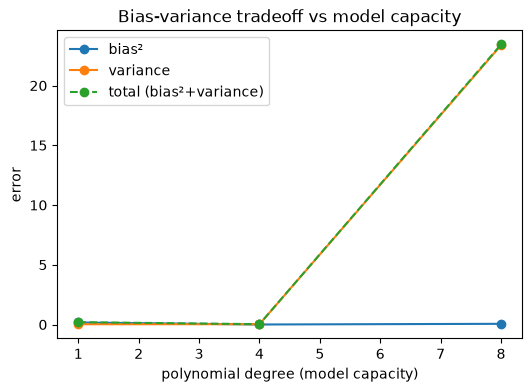

As capacity (degree) increases: bias² goes down, variance goes up -- the classic tradeoff.


In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(degrees_to_test, bias_sq_per_degree, marker="o", label="bias²")
ax.plot(degrees_to_test, variance_per_degree, marker="o", label="variance")
ax.plot(degrees_to_test, np.array(bias_sq_per_degree) + np.array(variance_per_degree),
        marker="o", linestyle="--", label="total (bias²+variance)")
ax.set_xlabel("polynomial degree (model capacity)"); ax.set_ylabel("error")
ax.set_title("Bias-variance tradeoff vs model capacity")
ax.legend()
plt.show()

print("As capacity (degree) increases: bias² goes down, variance goes up -- the classic tradeoff.")


## 2. L1 vs L2 vs Elastic Net: sparsity vs smooth shrinkage

⚠️ **Common Mistake:** treating L1 and L2 as interchangeable "regularization" -- they produce
qualitatively different weight patterns.

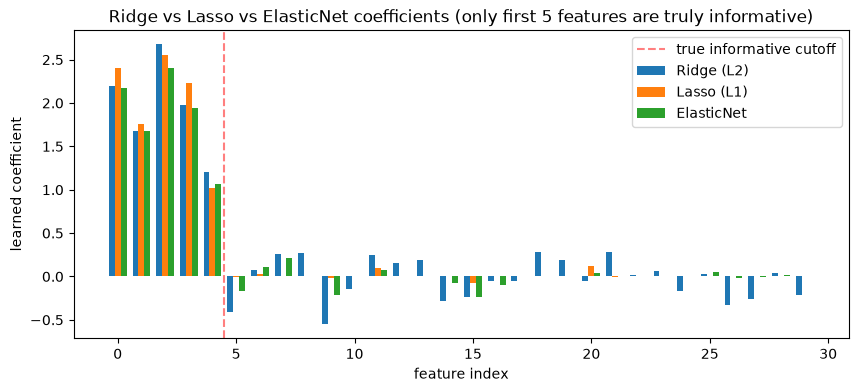

Lasso zeroed-out coefficients: 18 / 30
Ridge zeroed-out coefficients: 0 / 30


In [4]:
n_samples, n_features, n_informative = 50, 30, 5
true_coef = np.zeros(n_features)
true_coef[:n_informative] = rng.uniform(1, 3, size=n_informative)   # only 5 features matter

X = rng.normal(size=(n_samples, n_features))
y = X @ true_coef + rng.normal(scale=0.5, size=n_samples)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

ridge = Ridge(alpha=1.0).fit(X_train, y_train)
lasso = Lasso(alpha=0.1).fit(X_train, y_train)
elastic = ElasticNet(alpha=0.1, l1_ratio=0.5).fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(10, 4))
width = 0.25
x_pos = np.arange(n_features)
ax.bar(x_pos - width, ridge.coef_, width, label="Ridge (L2)")
ax.bar(x_pos, lasso.coef_, width, label="Lasso (L1)")
ax.bar(x_pos + width, elastic.coef_, width, label="ElasticNet")
ax.axvline(n_informative - 0.5, color="red", linestyle="--", alpha=0.5, label="true informative cutoff")
ax.set_xlabel("feature index"); ax.set_ylabel("learned coefficient")
ax.set_title("Ridge vs Lasso vs ElasticNet coefficients (only first 5 features are truly informative)")
ax.legend()
plt.show()

n_zero_lasso = np.sum(np.abs(lasso.coef_) < 1e-6)
n_zero_ridge = np.sum(np.abs(ridge.coef_) < 1e-6)
print(f"Lasso zeroed-out coefficients: {n_zero_lasso} / {n_features}")
print(f"Ridge zeroed-out coefficients: {n_zero_ridge} / {n_features}")
assert n_zero_lasso > n_zero_ridge   # L1 produces sparsity, L2 essentially never does


## 3. Effect of regularization strength

💡 **Key Idea:** as `alpha` increases, coefficients shrink toward zero -- too much regularization
underfits, too little overfits.

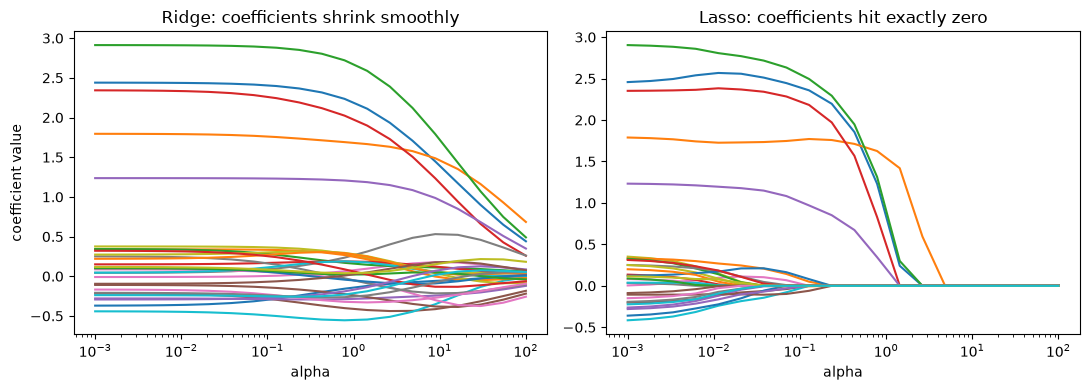

In [5]:
alphas = np.logspace(-3, 2, 20)
ridge_coef_paths = np.array([Ridge(alpha=a).fit(X_train, y_train).coef_ for a in alphas])
lasso_coef_paths = np.array([Lasso(alpha=a, max_iter=5000).fit(X_train, y_train).coef_ for a in alphas])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(alphas, ridge_coef_paths)
axes[0].set_xscale("log"); axes[0].set_title("Ridge: coefficients shrink smoothly")
axes[0].set_xlabel("alpha"); axes[0].set_ylabel("coefficient value")

axes[1].plot(alphas, lasso_coef_paths)
axes[1].set_xscale("log"); axes[1].set_title("Lasso: coefficients hit exactly zero")
axes[1].set_xlabel("alpha")
plt.tight_layout(); plt.show()


## 4. Early stopping

💡 **Intuition:** track both training and validation loss during an iterative fit; stop once
validation loss hasn't improved for a patience window, even though training loss would keep
dropping.

early stopping at epoch 42 (best epoch was 32)


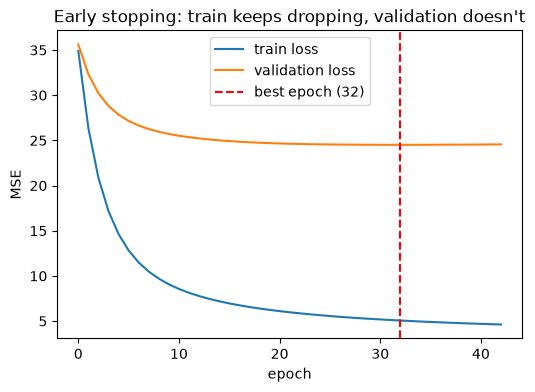

In [6]:
# Deliberately near the interpolation threshold (few more training samples than features) with
# heavy label noise: this is what makes gradient descent genuinely overfit -- early steps fit
# the true signal, later steps start fitting training-set noise specifically, which is exactly
# when validation loss turns upward even though training loss keeps falling.
n_features_big = 20
n_train_big = 28
X_train_big = rng.normal(size=(n_train_big, n_features_big))
X_val_big = rng.normal(size=(300, n_features_big))
true_coef_big = rng.uniform(-2, 2, size=n_features_big)
y_train_big = X_train_big @ true_coef_big + rng.normal(scale=4.0, size=n_train_big)
y_val_big = X_val_big @ true_coef_big + rng.normal(scale=4.0, size=300)

w = np.zeros(n_features_big)
lr = 0.05
train_losses, val_losses = [], []
best_val_loss = np.inf
best_epoch = 0
patience = 10
epochs_since_improvement = 0

for epoch in range(2000):
    train_pred = X_train_big @ w
    train_grad = (2 / len(y_train_big)) * X_train_big.T @ (train_pred - y_train_big)
    w -= lr * train_grad

    train_loss = np.mean((X_train_big @ w - y_train_big) ** 2)
    val_loss = np.mean((X_val_big @ w - y_val_big) ** 2)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_since_improvement = 0
    else:
        epochs_since_improvement += 1
        if epochs_since_improvement >= patience:
            print(f"early stopping at epoch {epoch} (best epoch was {best_epoch})")
            break

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(train_losses, label="train loss")
ax.plot(val_losses, label="validation loss")
ax.axvline(best_epoch, color="red", linestyle="--", label=f"best epoch ({best_epoch})")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.set_title("Early stopping: train keeps dropping, validation doesn't")
ax.legend()
plt.show()

assert best_epoch < len(train_losses) - 1   # stopped before training loss fully bottomed out


## 5. Connection to what's next

The same train-vs-validation tracking used for early stopping here becomes the basis of
`12_ml_evaluation`'s cross-validation and `14_hyperparameter_tuning`'s search strategies —
both are about reliably measuring generalization, not training performance.

## 6. Interview questions
1. Why does increasing model capacity typically increase variance and decrease bias?
2. Why does L1 regularization zero out coefficients while L2 only shrinks them?
3. What would happen to the bias-variance curve if you increased the number of training samples instead of changing model capacity?
4. Why is early stopping considered regularization even though no penalty term is added to the loss?
5. When would Elastic Net be preferable to pure L1 or pure L2?

## 7. Exercises
1. Repeat the bias-variance experiment with more training samples per trial (e.g. 100 instead of 20) and see how the curves shift.
2. Tune `alpha` for Lasso via a validation set to find the value that best recovers the true 5 informative features.
3. Add L2 regularization to the early-stopping gradient descent loop and compare how much it delays (or prevents) the need for early stopping.

## 8. Summary

✅ Bias-variance tradeoff explains why both too-simple and too-complex models generalize
poorly; L1/L2/Elastic Net buy down variance at the cost of some bias, each with a different
weight pattern; early stopping regularizes "for free" by watching validation loss. Next:
`12_ml_evaluation`.